In [2]:
# prep
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

df = pd.read_csv("health_study_dataset.csv")

           age   weight     height  systolic_bp  cholesterol
mean  49.42625   73.413  171.84925   149.178625      4.92915
50%   50.00000   73.200  171.35000   149.400000      4.97000
min   18.00000   33.700  144.40000   106.800000      2.50000
max   90.00000  114.400  200.40000   185.900000      7.88000


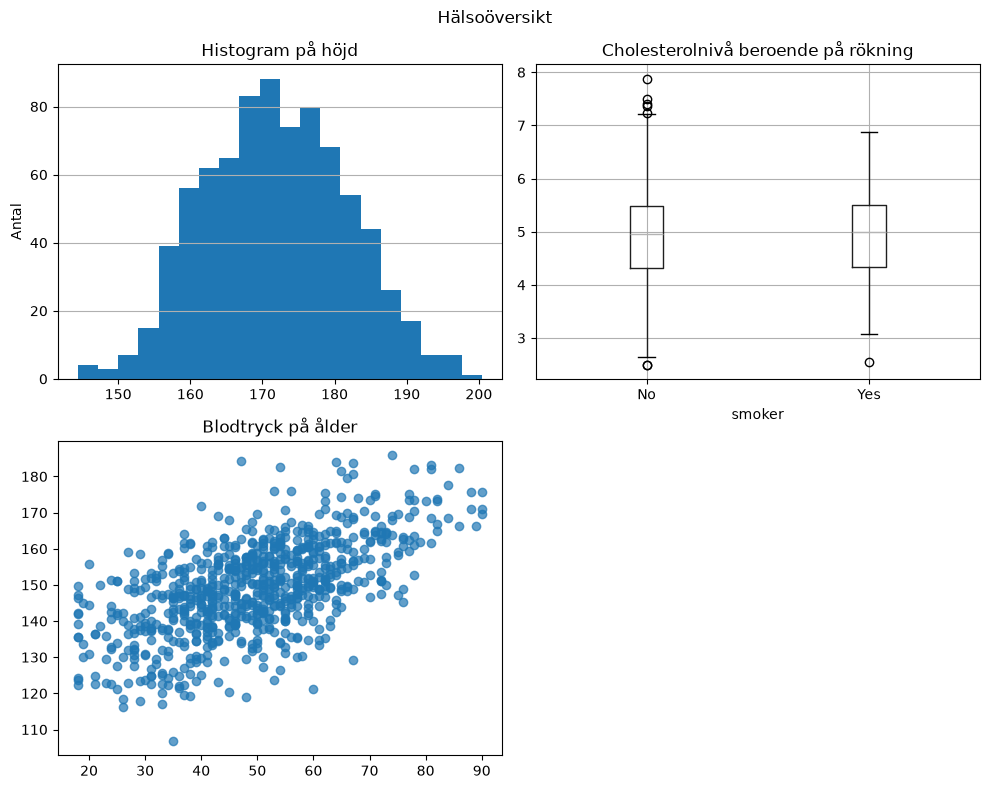

In [4]:
# Beskrivande analys
df_overview = df.describe().loc[['mean','50%', 'min', 'max'], 
                  ('age', 'weight', 'height', 'systolic_bp', 'cholesterol')]
print(f"{df_overview}")

# figur med tre grafer
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=False, sharey=False)

# 1. histogram för höjd
axes[0,0].hist(df.height, bins=20)
axes[0,0].set_title("Histogram på höjd")
axes[0,0].set_ylabel("Antal")
axes[0,0].grid(True, axis="y")

# 2. boxplot på cholesterol på rökning
df.boxplot(column="cholesterol", by="smoker", ax=axes[0,1])
axes[0,1].set_title("Cholesterolnivå beroende på rökning")

# 3. scatterplot för ålder x blodtryck
axes[1,0].scatter(df["age"], df["systolic_bp"], alpha=0.7)
axes[1,0].set_title("Blodtryck på ålder")

axes[1,1].axis("off")
fig.suptitle("Hälsoöversikt")
plt.tight_layout()



In [ ]:
# Simulering på sjukdomsfall
disease = df.disease.sum() / df.disease.count()
print("Andel personer i datasettet med sjukdomen", disease)  #0.05875, eller 5,875%

np.random.seed(587)
B = 1000
n = len(df.disease)
x = np.asarray(df.disease, dtype=float)
boot_stats = np.empty(B)

for b in range(B):
    boot = np.random.choice(x, size=n, replace=True)
    boot_stats[b] = np.mean(boot)

diff_mean = disease - np.mean(boot_stats)
variance = boot_stats.var(ddof=1)
lower = np.percentile(boot_stats, 2.5)
upper = np.percentile(boot_stats, 97.5)

print("Medelvärde i boostrap:", np.mean(boot_stats))
print("Skillnad i medelvärde:", diff_mean)
print(f"95 % bootstrap CI: {lower}, {upper}")
print("Varians:", variance)

Andel personer i datasettet med sjukdomen 0.05875
Medelvärde i boostrap: 0.058465
Skillnad i medelvärde: 0.0002849999999999936
Varians: 6.808373373373374e-05
95 % bootstrap CI: 0.04375, 0.07625


In [47]:
# Konfidensintervall
bp = np.asarray(df.systolic_bp, dtype=float)
mean_bp = float(np.mean(bp))
std = float(np.std(bp, ddof=1))
n = len(bp)
half_width = 1.96 * std / np.sqrt(n)
lower = mean_bp - half_width
upper = mean_bp + half_width

print(f"Konfidensintervall för blodtryck (systolic_bp) = {round(lower, 3)}, {round(upper, 3)}")

Konfidensintervall för blodtryck (systolic_bp) = 148.292, 150.065


In [49]:
# Hypotesprövning
smoker = df.loc[df.smoker == "Yes", "systolic_bp"].values
nonsmoker = df.loc[df.smoker == "No", "systolic_bp"].values

print(f"Medelvärde blodtryck \n För rökare: {np.mean(smoker)} \n För icke-rökare: {np.mean(nonsmoker)}")
print("Differens: ", round(np.mean(smoker)-np.mean(nonsmoker), 4))

t_stat, p_val = stats.ttest_ind(smoker, nonsmoker, equal_var=False)
print("\nResultat på Welch t-test: ", t_stat, "\np-värde: ", p_val)

s = smoker.var(ddof=1)
ns = nonsmoker.var(ddof=1)
sp = np.sqrt((len(smoker)-1)*s + (len(nonsmoker)-1)*ns / (len(smoker) + len(nonsmoker)-2))
cohens_d = ((np.mean(nonsmoker) - np.mean(smoker)) / sp)
print("\nEffektstorlek: ", cohens_d)

Medelvärde blodtryck 
 För rökare: 149.524882629108 
 För icke-rökare: 149.05298126064736
Differens:  0.4719

Resultat på Welch t-test:  0.4503433193393224 
p-värde:  0.6527338743398997

Effektstorlek:  -0.0024389578353825013


Genom att jämföra medelvärdena på rökares och icke-rökares blodtryck går det att se att rökare har högre blodtryck med ungefär 0,5. Detta är dock inte en tillräcklig stor skillnad för att vara noterbar, eller signifikant. P-värdet är långt över målet på 0,05, och även om den hade varit på en signifikant nivå så visar Cohens d att effektstorleken är väldigt liten. Det går därför att avslå hypotesen och göra en slutsats baserat på denna data att rökare inte har högre medel-blodtryck än icke-rökare.